# 보행망 400m에서 서울 따릉이 수요 예측

대여소 2,766곳을 같은 군집 내 모든 쌍의 보행거리가 400m 이하가 되도록 묶는다. 도보 접근을 위한 고정 가정이며 이용자의 실측 보행 의향을 뜻하지 않는다. 700m 실험과 같은 보행망·거리 행렬·완전연결 트리를 사용하며 거리 기준만 바꾼다.

2024년 12월 명단과 2025-01-01 [Geofabrik 대한민국 지도](https://download.geofabrik.de/asia/south-korea.html)를 고정한 회고 분석이다. 지도 데이터와 파생 배정 © [OpenStreetMap 기여자](https://www.openstreetmap.org/copyright), ODbL 1.0. Python 3.11, osmium, pyproj, shapely, scipy, pandas, scikit-learn, pyarrow, PyTorch와 README의 필터 처리된 2023·2024년 대여 ZIP 2개가 필요하다. 월별 집계가 있으면 환경변수 BIKE_AGGREGATE_CACHE로 재사용한다.

In [1]:
from pathlib import Path
import hashlib, os, sys, tempfile
from urllib.request import urlretrieve
import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"전처리/walking_network.py").is_file())
SITE = ROOT/"따릉이 대여소 비교"
sys.path.insert(0,str(ROOT/"전처리"))
from walking_network import station_distances
stations = pd.read_csv(SITE/"실루엣 선택 군집 배정.csv").set_index("대여소번호").sort_index()
assert len(stations) == stations.index.nunique() == 2766
url = "https://download.geofabrik.de/asia/south-korea-250101.osm.pbf"
pbf = Path(os.getenv("SEOUL_WALK_PBF", str(Path(tempfile.gettempdir())/"south-korea-250101.osm.pbf")))
if not pbf.is_file():
    part = pbf.with_suffix(".part")
    urlretrieve(url, part)
    part.replace(pbf)
assert pbf.stat().st_size == 233753476
with pbf.open("rb") as data:
    digest = hashlib.file_digest(data, "sha256").hexdigest()
assert digest=="9b67fc951d535639b2a12e96a0ff069943d6da4d75883e42d377e6f76c7483ab"
print("PBF SHA-256", digest)
distance, access, graph_stats = station_distances(stations, pbf)
print(graph_stats)

PBF SHA-256 9b67fc951d535639b2a12e96a0ff069943d6da4d75883e42d377e6f76c7483ab


{'eligible_segments': 1076273, 'main_component_segments': 1062889, 'stations': 2766, 'snap_median_m': 8.909919511937737, 'snap_p95_m': 22.754103217532023, 'snap_max_m': 108.99088395499034}


In [2]:
tree = linkage(squareform(distance), method="complete")
def cut_at(metres):
    raw = pd.Series(fcluster(tree, metres, criterion="distance"), index=stations.index)
    return raw.groupby(raw).transform(lambda members: members.index.min())

reference = pd.read_csv(SITE/"보행망 군집 배정.csv").set_index("대여소번호").sort_index()
np.testing.assert_array_equal(stations.index, reference.index)
np.testing.assert_array_equal(cut_at(700), reference["보행망 군집번호"])
np.testing.assert_allclose(access,reference["보행로 접속거리(m)"])
group = cut_at(400).rename("보행망 400m 군집번호")
maximum = group.groupby(group).indices
assert all(distance[np.ix_(rows,rows)].max() <= 400+1e-7 for rows in maximum.values())
score400 = silhouette_score(distance,group,metric="precomputed")
old400 = pd.read_csv(SITE/"보행망 거리별 실루엣.csv").set_index("최대거리(m)").loc[400]
assert group.nunique()==old400["군집 수"]
np.testing.assert_allclose(score400,old400["평균 실루엣"])
assignment = reference[["대여소명","자치구","위도","경도","보행로 접속거리(m)"]].copy()
assignment[group.name] = group
assignment["보행망 700m 군집번호"] = reference["보행망 군집번호"]
assignment["400m 군집 크기"] = group.map(group.value_counts())
assignment.to_csv(SITE/"보행망 400m 군집 배정.csv",encoding="utf-8-sig")
print(f"400m 군집 {group.nunique():,}개, 단독 {(group.value_counts()==1).sum():,}개, 평균 실루엣 {score400:.5f}")
del distance

400m 군집 1,592개, 단독 736개, 평균 실루엣 0.32606


## 군집별 대여·반납량과 시계열 입력

In [3]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "전처리/walking_forecast.py").is_file())
OUT = ROOT / "모델"
SITE = ROOT / "따릉이 대여소 비교"
sys.path.insert(0,str(ROOT/"전처리"))
from walking_forecast import (hours, count_departures, prepare_inputs, ClusterNet, VARIANTS,
                              DEVICE, BATCH, EPOCHS, SEED)
from torch import nn
import math

limit = 400
ids = pd.Index(sorted(group.unique()),name="군집번호")
N = len(ids)
totals, late_returns, confirmed = count_departures(group)
np.testing.assert_array_equal([totals[hours.year==y].sum() for y in (2023,2024)], [42810716,42219615])
context_at, batch_inputs, past, actual, weather_names = prepare_inputs(group,totals,late_returns,confirmed)
print(f"보행망 {limit}m, {N}개 군집 / 학습 장치 {DEVICE}")

보행망 400m, 1592개 군집 / 학습 장치 cuda


## 다음 1시간 대여량 예측의 기준선

각 군집에서 전날 같은 시간 또는 전주 같은 시간의 대여량을 그대로 예측값으로 사용한다. 당시까지 반납이 확인된 건수만 입력에 포함한다. 2024년 각 분기의 동일한 군집·시간 전체에서 비교한다. 오차 단위는 한 군집의 한 시간당 대여 건수다. 12월 군집을 사용했으므로 이 결과는 회고 비교로 해석한다.

In [4]:
scores = []
for lag in (24, 168):
    observed = totals[:-lag] - late_returns[lag][lag:]
    assert observed.min() >= 0
    dates = hours[lag:]
    for quarter in range(1,5):
        selected = (dates.year == 2024) & (dates.quarter == quarter)
        error = (totals[lag:][selected] - observed[selected]).astype("float64")
        scores.append([quarter, "전날 동일 시간" if lag == 24 else "전주 동일 시간",
                       error.size, np.abs(error).mean(), np.sqrt(np.square(error).mean())])
scores = pd.DataFrame(scores, columns=["분기","기준선","군집·시간 수","MAE","RMSE"])
assert scores.groupby("기준선")["군집·시간 수"].sum().eq((hours.year==2024).sum()*len(ids)).all()
display(scores.pivot(index="분기",columns="기준선",values=["MAE","RMSE"]).round(3))

MAE              RMSE         
기준선 전날 동일 시간 전주 동일 시간 전날 동일 시간 전주 동일 시간
분기                                     
1      1.526    1.469    3.056    2.851
2      2.534    2.418    4.909    4.639
3      2.207    2.181    4.264    4.206
4      1.926    1.851    3.912    3.607

## MLP·GRU를 네 입력 조건에서 새로 학습

한 모델이 모든 군집에서 학습하며 각 군집의 다음 한 시간 출발량을 예측한다. 기본 입력은 군집 임베딩, 반납이 확인된 직전 24시간·전주 동일 시간의 출발량, 달력과 직전 날씨다. 반납량만, 유사 기상만, 둘 다 추가한 버전도 각각 처음부터 학습한다. MLP는 시퀀스를 펼쳐서 읽고 GRU는 시간순으로 읽는다. 모든 조건에서 기존 실험과 동일한 MSE, Adam 0.001, 배치 8,192, 4에포크, 시드 42를 사용한다. 분기 경계 전에 확인될 수 있었던 학습 정답만 쓴다.

MLP는 은닉층 64·32와 ReLU를 사용하고, GRU는 과거 24시간을 은닉 크기 16으로 요약해 같은 구조의 출력층에 입력한다. 최종 활성화는 Softplus다. 네트워크와 입력 변환은 [공유 코드](../전처리/walking_forecast.py)에 있다.

In [5]:
def train_model(kind, cutoff, context, variant):
    torch.manual_seed(SEED)
    model = ClusterNet(kind, context.shape[1], len(VARIANTS[variant][1]), N).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
    loss_fn = nn.MSELoss()
    # t + 24 <= cutoff이고 전주 동일 시간 관측이 있는 모든 학습 행을 사용한다.
    n_rows = (cutoff - 23 - 168) * N
    for epoch in range(EPOCHS):
        model.train()
        order = torch.randperm(n_rows,device=DEVICE)
        for ix in order.split(BATCH):
            t,g,seq,historical_features = batch_inputs(ix + 168*N, variant)
            pred = model(seq,historical_features,context[t],g)
            loss = loss_fn(pred,past[t,g,23].float())
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5.)
            optimizer.step()
    return model

@torch.inference_mode()
def evaluate(model, start, stop, context, variant):
    model.eval()
    sums = torch.zeros(2,device=DEVICE,dtype=torch.float64)
    for begin in range(start*N,stop*N,BATCH):
        flat = torch.arange(begin,min(stop*N,begin+BATCH),device=DEVICE)
        t,g,seq,historical_features = batch_inputs(flat, variant)
        err = (model(seq,historical_features,context[t],g) - actual[t,g]).double()
        sums += torch.stack([err.abs().sum(),err.square().sum()])
    n_rows = (stop-start)*N
    mae, mse = (sums/n_rows).cpu().tolist()
    assert math.isfinite(mae) and math.isfinite(mse)
    return n_rows, mae, math.sqrt(mse)

## 같은 지역을 예측하는 4분기 비교

400m 군집은 각각 하나의 700m 군집에 속한다. 400m 예측을 700m 군집 1,009개 및 기존의 공통 구역 632개에 합산한다. 두 구획에서 같은 전주 기준선도 대조한다.

In [6]:
zone_map = pd.read_csv(SITE/"보행망 직선거리 공통 평가구역.csv").set_index("대여소번호").sort_index()
np.testing.assert_array_equal(zone_map.index, group.index)
np.testing.assert_array_equal(zone_map["보행망 선택"],assignment["보행망 700m 군집번호"])
parent_columns = {"보행망 700m":assignment["보행망 700m 군집번호"],"기존 공통구역":zone_map["공통구역"]}
positions, zone_truth = {}, {}
q4 = hours.get_loc(pd.Timestamp("2024-10-01 00:00"))
def aggregate(values, position):
    combined = np.zeros((len(values), int(position.max())+1), dtype="float64")
    np.add.at(combined.T, position, values.T)
    return combined
for scope, labels in parent_columns.items():
    mapping = labels.groupby(group)
    assert mapping.nunique().eq(1).all()
    parent_ids = pd.Index(sorted(labels.unique()))
    positions[scope] = parent_ids.get_indexer(mapping.first().loc[ids])
    assert (positions[scope]>=0).all()
    zone_truth[scope] = aggregate(totals[q4:],positions[scope])
    np.testing.assert_array_equal(zone_truth[scope].sum(axis=1),totals[q4:].sum(axis=1))
    print(scope,len(parent_ids),"개 구역")
def errors(pred, truth):
    diff = pred - truth
    return np.abs(diff).mean(), np.sqrt(np.square(diff).mean())
def collect_common(model, context, variant, kind, label):
    # 같은 네트워크 출력을 두 공간 단위로 합산한다. 예측값은 반올림하지 않는다.
    flat_pred = np.empty(totals[q4:].size,dtype="float32")
    model.eval()
    with torch.inference_mode():
        for i in range(0,len(flat_pred),BATCH):
            j = min(i+BATCH,len(flat_pred))
            t,g,seq,hist = batch_inputs(torch.arange(q4*N+i,q4*N+j,device=DEVICE),variant)
            flat_pred[i:j] = model(seq,hist,context[t],g).cpu().numpy()
    pred = flat_pred.reshape(totals[q4:].shape)
    for scope,pos in positions.items():
        target = zone_truth[scope]
        mae,rmse = errors(aggregate(pred,pos),target)
        common_rows.append([scope, "보행망 400m", kind,label,target.shape[1],target.size,mae,rmse])
    return errors(pred.astype("float64"),totals[q4:])
common_rows = []

보행망 700m 1009 개 구역


기존 공통구역 632 개 구역


In [7]:
neural = []
for quarter, begin in enumerate(pd.date_range("2024-01-01","2024-10-01",freq="QS"),1):
    start = int(hours.searchsorted(begin))
    stop = int(hours.searchsorted(begin + pd.DateOffset(months=3)))
    context, scaling = context_at(start)
    for variant, (label, feature_names) in VARIANTS.items():
        for kind in ("MLP","GRU"):
            model = train_model(kind,start,context,variant)
            size,mae,rmse = evaluate(model,start,stop,context,variant)
            assert size == (stop-start)*N
            neural.append([quarter,kind,label,size,mae,rmse])
            print(f"{quarter}분기 {kind} {label} · MAE {mae:.4f}, RMSE {rmse:.4f}",flush=True)
            if quarter == 4:
                native = collect_common(model,context,variant,kind,label)
                np.testing.assert_allclose(native,[mae,rmse],rtol=2e-5,atol=2e-5)
                checkpoint = {"kind":kind,"weights":model.cpu().state_dict(),"cluster_ids":list(map(int,ids)),
                              "cluster_limit_m":limit,"context_size":context.shape[1],"weather":weather_names,"variant":variant,
                              "extra_features":feature_names,"scaling":scaling,"seed":SEED,
                              "epochs":EPOCHS,"cutoff":str(begin)}
                torch.save(checkpoint, OUT / f"walking400_{kind.lower()}_{variant}.pt")
            del model
individual = pd.DataFrame(neural,columns=["분기","모델","추가 입력","군집·시간 수","MAE","RMSE"])


1분기 MLP 없음 · MAE 1.0925, RMSE 1.8997


1분기 GRU 없음 · MAE 1.0990, RMSE 1.8864


1분기 MLP 둘 다 · MAE 1.0761, RMSE 1.8498


1분기 GRU 둘 다 · MAE 1.0946, RMSE 1.8488


1분기 MLP 반납량만 · MAE 1.0702, RMSE 1.8497


1분기 GRU 반납량만 · MAE 1.0655, RMSE 1.8295


... (22 outputs left out)

4분기 MLP 반납량만 · MAE 1.3458, RMSE 2.2512


4분기 GRU 반납량만 · MAE 1.3358, RMSE 2.2294


4분기 MLP 유사 기상만 · MAE 1.3782, RMSE 2.2869


4분기 GRU 유사 기상만 · MAE 1.3022, RMSE 2.2097


## 400m 군집 자체에서의 분기별 성능

In [8]:
results = individual.copy()
keys = ["분기","모델","추가 입력"]
assert len(results)==32 and not results.duplicated(keys).any()
assert results.groupby("분기")["군집·시간 수"].nunique().eq(1).all()
assert np.isfinite(results[["MAE","RMSE"]]).all().all()
baseline = scores.loc[scores["기준선"]=="전주 동일 시간"].set_index("분기")
results["전주 대비 MAE 개선율(%)"] = 100*(1-results.MAE/results["분기"].map(baseline.MAE))
scores.to_csv(OUT/"보행망 400m 군집 기준선 성능.csv",index=False,encoding="utf-8-sig")
results.to_csv(OUT/"보행망 400m 군집 피처별 성능.csv",index=False,encoding="utf-8-sig")
order = ["없음","반납량만","유사 기상만","둘 다"]
for metric in ["MAE","RMSE"]:
    print(metric)
    display(results.pivot(index=["모델","분기"],columns="추가 입력",values=metric)[order].round(4))
display(results.loc[results["분기"]<=3].groupby(["모델","추가 입력"])[["MAE","RMSE"]].mean().round(4))


MAE


추가 입력       없음    반납량만  유사 기상만     둘 다
모델  분기                                
GRU 1   1.0990  1.0655  1.0895  1.0946
    2   1.6719  1.6056  1.6307  1.5860
    3   1.5193  1.4885  1.4943  1.4684
    4   1.3512  1.3358  1.3022  1.3212
MLP 1   1.0925  1.0702  1.0795  1.0761
    2   1.6938  1.6796  1.6270  1.6531
    3   1.5279  1.4947  1.4842  1.4556
    4   1.3256  1.3458  1.3782  1.3486

RMSE


추가 입력       없음    반납량만  유사 기상만     둘 다
모델  분기                                
GRU 1   1.8864  1.8295  1.8613  1.8488
    2   2.8746  2.7438  2.7384  2.6592
    3   2.6058  2.5425  2.5405  2.4754
    4   2.2767  2.2294  2.2097  2.1920
MLP 1   1.8997  1.8497  1.8606  1.8498
    2   2.9348  2.8556  2.7707  2.7763
    3   2.6317  2.5428  2.5269  2.5033
    4   2.2623  2.2512  2.2869  2.2691

MAE    RMSE
모델  추가 입력                 
GRU 둘 다     1.3830  2.3278
    반납량만    1.3865  2.3719
    없음      1.4301  2.4556
    유사 기상만  1.4048  2.3801
MLP 둘 다     1.3950  2.3765
    반납량만    1.4148  2.4161
    없음      1.4381  2.4887
    유사 기상만  1.3969  2.3861

## 같은 지역으로 합산한 결과

In [9]:
columns = ["평가 구획","학습 구획","모델","추가 입력","구역 수","구역·시간 수","MAE","RMSE"]
new = pd.DataFrame(common_rows,columns=columns)
previous = pd.read_csv(OUT/"보행망 직선거리 공통구역 4분기 비교.csv").rename(columns={"공통 구역 수":"구역 수"})
previous["학습 구획"] = previous["학습 구획"].replace({"보행망 선택":"보행망 700m"})
previous["평가 구획"] = "기존 공통구역"
direct = pd.read_csv(OUT/"보행망 군집 피처별 성능.csv").query("분기==4").rename(columns={"군집·시간 수":"구역·시간 수"})
direct = direct.assign(**{"평가 구획":"보행망 700m","학습 구획":"보행망 700m","구역 수":zone_truth["보행망 700m"].shape[1]})
weekly = totals[q4-168:-168]-late_returns[168][q4:]
for scope,pos in positions.items():
    baseline_score = errors(aggregate(weekly,pos),zone_truth[scope])
    if scope == "기존 공통구역":
        expected = previous[["공통 전주 MAE","공통 전주 RMSE"]].drop_duplicates()
    else:
        b = pd.read_csv(OUT/"보행망 군집 기준선 성능.csv")
        expected = b.loc[(b["분기"]==4)&(b["기준선"]=="전주 동일 시간"),["MAE","RMSE"]]
    assert len(expected)==1
    np.testing.assert_allclose(baseline_score,expected.iloc[0].to_numpy(dtype=float))
fair = pd.concat([new,previous[columns],direct[columns]],ignore_index=True)
assert len(fair)==48 and not fair.duplicated(columns[:4]).any()
assert fair.groupby("평가 구획")["구역·시간 수"].nunique().eq(1).all()
fair.to_csv(OUT/"보행망 400m 동일지역 4분기 비교.csv",index=False,encoding="utf-8-sig")
for scope in positions:
    print(scope)
    display(fair.loc[fair["평가 구획"]==scope].pivot(index=["모델","추가 입력"],columns="학습 구획",values="MAE").round(4))

보행망 700m


학습 구획       보행망 400m  보행망 700m
모델  추가 입력                     
GRU 둘 다       1.7215    1.6778
    반납량만      1.7436    1.6735
    없음        1.7609    1.7114
    유사 기상만    1.6875    1.6925
MLP 둘 다       1.7677    1.7556
    반납량만      1.7601    1.7325
    없음        1.7204    1.7221
    유사 기상만    1.8094    1.7477

기존 공통구역


학습 구획       보행망 400m  보행망 700m  직선 500m  직선 600m
모델  추가 입력                                       
GRU 둘 다       2.2500    2.1657   2.1338   2.1834
    반납량만      2.2781    2.1515   2.1477   2.2076
    없음        2.2978    2.2014   2.2304   2.2558
    유사 기상만    2.1859    2.1863   2.1867   2.1973
MLP 둘 다       2.3306    2.2930   2.1263   2.2023
    반납량만      2.3040    2.2411   2.2298   2.2443
    없음        2.2269    2.2227   2.3184   2.2360
    유사 기상만    2.3985    2.2759   2.1661   2.1814

## 같은 모델·피처에서 400m와 700m의 차이

0보다 작으면 400m 모델의 예측을 합산했을 때 MAE가 더 낮다.

C:\Users\dlwns\AppData\Local\Temp\ipykernel_32516\1147397593.py:23: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.tight_layout()
C:\Users\dlwns\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


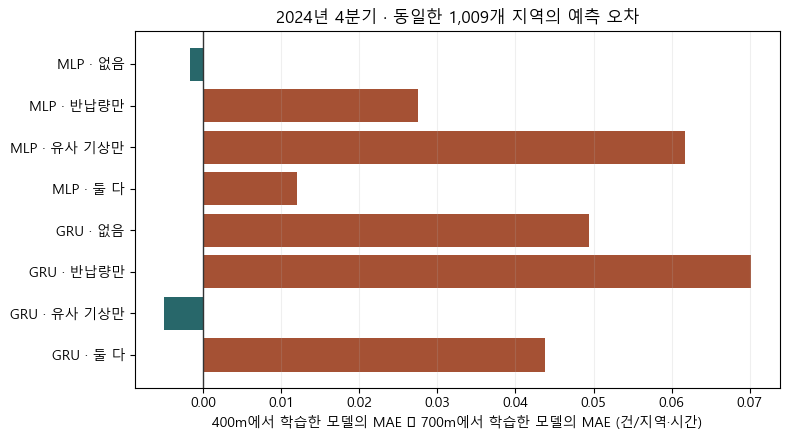

In [10]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"전처리/walking_forecast.py").is_file())
metrics = pd.read_csv(root/"모델/보행망 400m 동일지역 4분기 비교.csv")
comparison = metrics.loc[metrics["평가 구획"]=="보행망 700m"].pivot(
    index=["모델","추가 입력"],columns="학습 구획",values="MAE")
paired_delta = comparison["보행망 400m"] - comparison["보행망 700m"]
paired_delta = paired_delta.reindex([(kind, feature) for kind in ["MLP","GRU"]
                                      for feature in ["없음","반납량만","유사 기상만","둘 다"]])
plt.rcParams["font.family"] = "Malgun Gothic" if os.name=="nt" else "sans-serif"
plt.rcParams["axes.unicode_minus"] = False
fig,ax = plt.subplots(figsize=(8,4.5))
ax.barh([" · ".join(row) for row in paired_delta.index],paired_delta,
        color=["#28676a" if value<0 else "#a55134" for value in paired_delta])
ax.axvline(0,color="#333333",linewidth=1)
ax.set(title="2024년 4분기 · 동일한 1,009개 지역의 예측 오차",
       xlabel="400m에서 학습한 모델의 MAE − 700m에서 학습한 모델의 MAE (건/지역·시간)")
ax.invert_yaxis()
ax.grid(axis="x",alpha=.2)
fig.tight_layout()
plt.show()